In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Dense, Flatten
from keras.utils import to_categorical
from keras.datasets import mnist

In [ ]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()
print('x_train shape =', x_train.shape)
print('y_train shape =', y_train.shape)
print('x_test shape =', x_test.shape)
print('y_test shape =', y_test.shape)

x_train shape = (60000, 28, 28)
y_train shape = (60000,)
x_test shape = (10000, 28, 28)
y_test shape = (10000,)


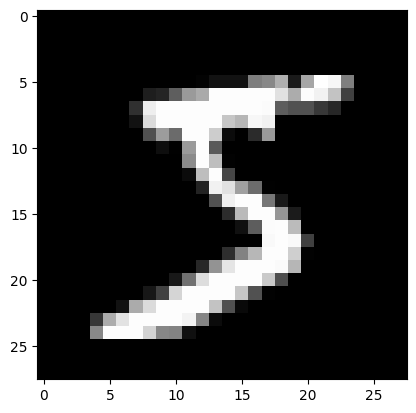

In [ ]:
plt.imshow(x_train[0], cmap='gray')

In [ ]:
y_train = to_categorical(y_train)
y_test = to_categorical(y_test)
print(y_train[0])

[0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]


In [ ]:
x_train = x_train.reshape(-1, 28*28)
x_test = x_test.reshape(-1, 28*28)
x_train = x_train/255.0
x_test = x_test/255.0

In [ ]:
model = Sequential()
model.add(Dense(256, activation='relu', input_shape=(784,)))
model.add(Dense(256, activation='relu'))
model.add(Dense(128, activation='relu'))
model.add(Dense(64, activation='relu'))
model.add(Dense(10, activation = 'softmax'))

In [ ]:
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics = ['accuracy'])
model.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_24 (Dense)                     │ (None, 256)                 │         200,960 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_25 (Dense)                     │ (None, 256)                 │          65,792 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_26 (Dense)                     │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_27 (Dense)                     │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_28 (Dense)                     │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 308,554 (1.18 MB)

 Trainable params: 308,554 (1.18 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = model.fit(x_train, y_train, batch_size=64, epochs=10, validation_data=(x_test, y_test))

Epoch 1/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 10s 9ms/step - accuracy: 0.8746 - loss: 0.4229 - val_accuracy: 0.9652 - val_loss: 0.1116
Epoch 2/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - accuracy: 0.9716 - loss: 0.0945 - val_accuracy: 0.9699 - val_loss: 0.0981
Epoch 3/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.9802 - loss: 0.0638 - val_accuracy: 0.9699 - val_loss: 0.0960
Epoch 4/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - accuracy: 0.9835 - loss: 0.0509 - val_accuracy: 0.9757 - val_loss: 0.0796
Epoch 5/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 9s 8ms/step - accuracy: 0.9880 - loss: 0.0363 - val_accuracy: 0.9723 - val_loss: 0.1043
Epoch 6/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - accuracy: 0.9892 - loss: 0.0341 - val_accuracy: 0.9778 - val_loss: 0.0748
Epoch 7/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 11s 9ms/step - accuracy: 0.9917 - loss: 0.0257 - val_accuracy: 0.9778 - val_loss: 0.0846
Epoch 8/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 10s 9ms/step - accuracy: 0.9929 - loss: 0.0226 - val_accuracy

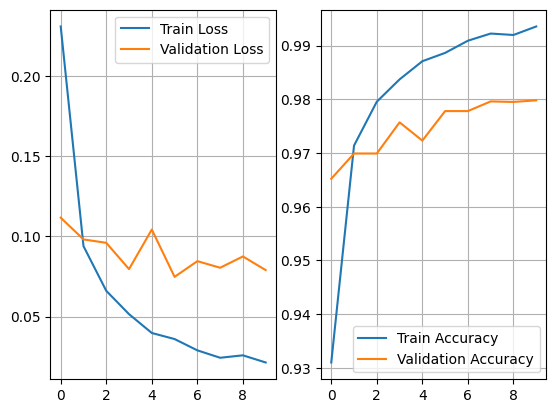

In [ ]:
loss = history.history["loss"]
acc = history.history["accuracy"]
val_loss = history.history["val_loss"]
val_acc = history.history["val_accuracy"]
plt.subplot(1,2,1)
plt.plot(range(len(loss)), loss, label = "Train Loss")
plt.plot(range(len(val_loss)), val_loss, label = "Validation Loss")
plt.grid()
plt.legend()
plt.subplot(1,2,2)
plt.plot(range(len(acc)), acc, label = "Train Accuracy")
plt.plot(range(len(val_acc)), val_acc, label = "Validation Accuracy")
plt.grid()
plt.legend()
plt.show()

In [ ]:
score = model.evaluate(x_test, y_test)
print('Test loss : ', score[0])
print('Test Accuracy : ', score[1])

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9768 - loss: 0.0967
Test loss :  0.07900022715330124
Test Accuracy :  0.9797999858856201


In [ ]:
wrong_index_list = []
predict = model.predict(x_test)
for index in range(10000):
  if np.argmax(y_test[index]) != np.argmax(predict[index]):
    wrong_index_list.append(index)
print(wrong_index_list)
print("총 틀린 갯수 : ", len(wrong_index_list))

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
[115, 121, 149, 151, 247, 321, 340, 445, 447, 495, 511, 582, 610, 619, 646, 674, 707, 720, 740, 846, 881, 900, 936, 947, 951, 1014, 1039, 1112, 1156, 1159, 1178, 1226, 1242, 1247, 1260, 1319, 1328, 1393, 1395, 1522, 1530, 1549, 1609, 1621, 1626, 1670, 1678, 1681, 1709, 1878, 1901, 1941, 2004, 2024, 2035, 2043, 2053, 2070, 2098, 2118, 2135, 2185, 2189, 2291, 2293, 2329, 2387, 2488, 2597, 2607, 2648, 2654, 2659, 2939, 3005, 3023, 3030, 3062, 3073, 3117, 3225, 3289, 3333, 3377, 3384, 3405, 3451, 3457, 3475, 3490, 3503, 3520, 3558, 3559, 3718, 3726, 3780, 3796, 3811, 3853, 3869, 3876, 3902, 3906, 3941, 3943, 3976, 4065, 4078, 4116, 4156, 4176, 4238, 4248, 4265, 4360, 4425, 4477, 4497, 4536, 4567, 4731, 4751, 4761, 4807, 4823, 4880, 5331, 5457, 5642, 5676, 5757, 5842, 5887, 5888, 5926, 5936, 5937, 5955, 5973, 5975, 5982, 6011, 6059, 6071, 6091, 6101, 6166, 6391, 6560, 6574, 6576, 6597, 6632, 6641, 6651, 6755, 6783, 7100, 7216, 7338, 7434, 8059, 8094,

In [ ]:
import random

samples = random.choices(population=wrong_index_list, k = 16)
samples

[3906,
 9808,
 1621,
 3062,
 6632,
 3811,
 4823,
 445,
 1156,
 2939,
 8508,
 5982,
 3225,
 1522,
 9808,
 8128]

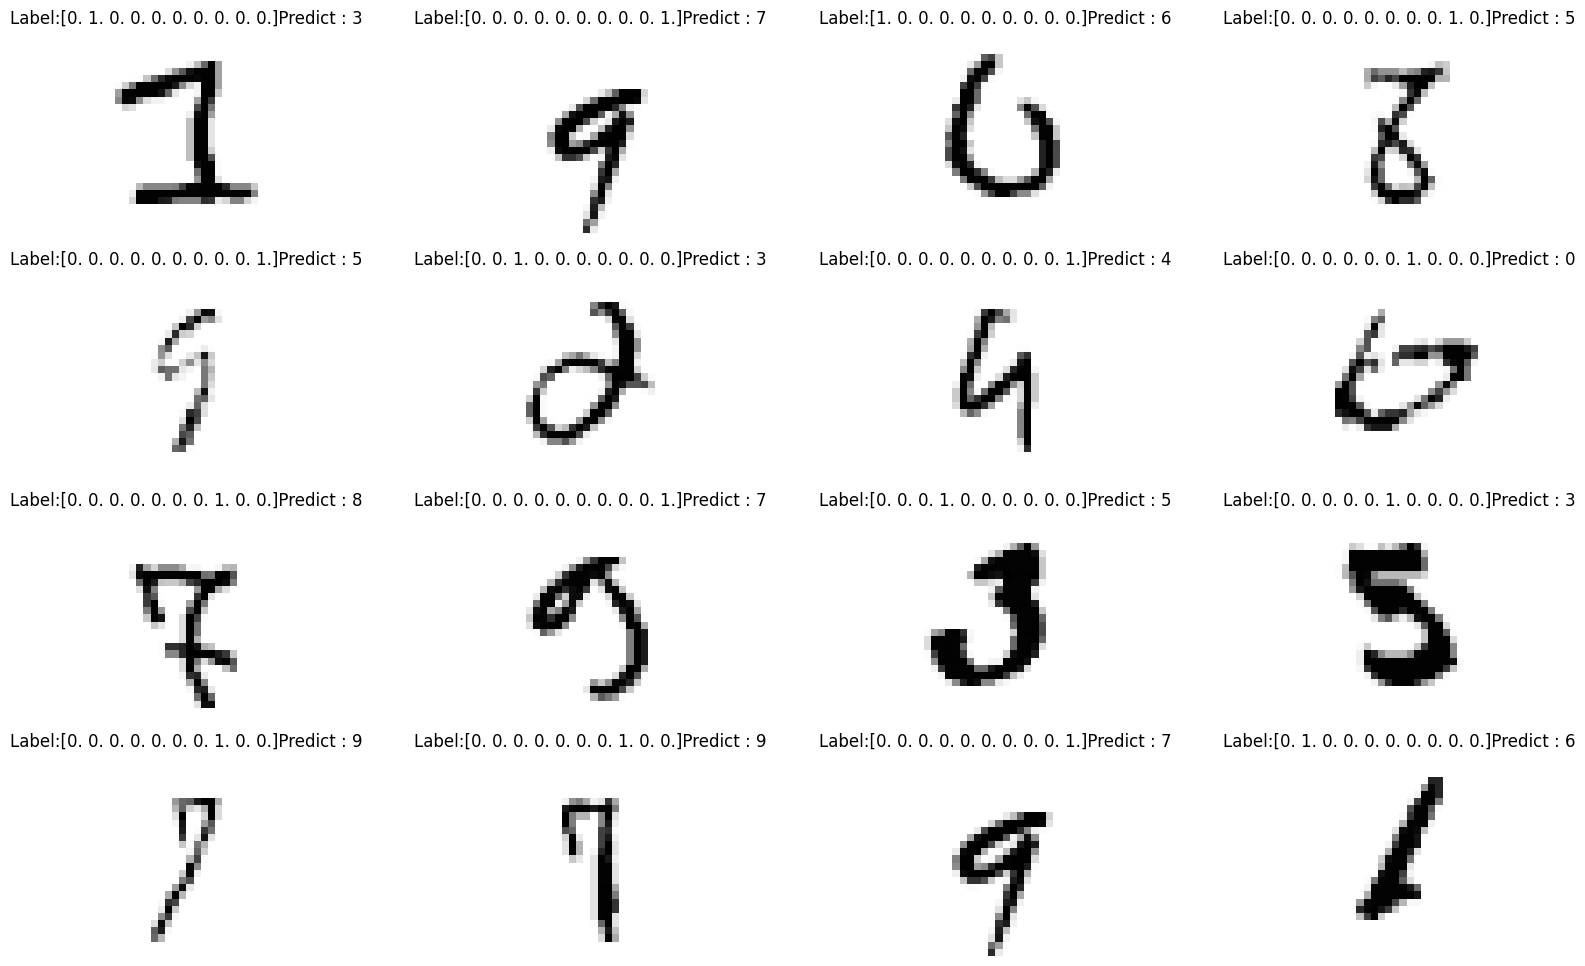

In [ ]:
plt.figure(figsize=(20,12))

for idx, n in enumerate(samples):
  plt.subplot(4,4,idx+1)
  plt.imshow(x_test[n].reshape(28,28), cmap = 'Greys', interpolation = 'nearest')
  plt.title('Label:' + str(y_test[n]) + 'Predict : ' + str(np.argmax(predict[n])))
  plt.axis('off')

plt.show()